In [28]:
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

def calculate_exact_distance(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1_rad, lon1_rad = np.radians(lat1), np.radians(lon1)
    lat2_rad, lon2_rad = np.radians(lat2), np.radians(lon2)

    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad

    a = np.sin(dlat / 2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    # 30% added for Ethiopian road sinuosity
    actual_road_distance = (R * c) * 1.3

    return np.round(actual_road_distance, 2)

In [29]:
n_samples = 250000
np.random.seed(42)

real_locations = {
    'Djibouti_Doraleh': (11.5950, 42.9975),
    'Djibouti_Galafi': (11.7194, 41.8389),
    'Modjo_Dry_Port': (8.5885, 39.1211),
    'Addis_Kality': (8.9221, 38.7615),
    'Semera_Hub': (11.7944, 41.0086),
    'Awash_Checkpoint': (8.9833, 40.1667),
    'Adama_Nazreth': (8.5414, 39.2705),
    'Dire_Dawa': (9.6009, 41.8501),
    'Mekelle_Hub': (13.4967, 39.4753)
}

location_names = list(real_locations.keys())

origin_choices = np.random.choice(['Djibouti_Doraleh', 'Modjo_Dry_Port'], size=n_samples, p=[0.80, 0.20])
dest_choices = np.random.choice(location_names, size=n_samples)

# Dynamic resampling to prevent Origin == Destination
mask = origin_choices == dest_choices
while mask.any():
    dest_choices[mask] = np.random.choice(location_names, size=mask.sum())
    mask = origin_choices == dest_choices

origin_lat = np.array([real_locations[loc][0] for loc in origin_choices])
origin_lon = np.array([real_locations[loc][1] for loc in origin_choices])
dest_lat = np.array([real_locations[loc][0] for loc in dest_choices])
dest_lon = np.array([real_locations[loc][1] for loc in dest_choices])

distance_km = calculate_exact_distance(origin_lat, origin_lon, dest_lat, dest_lon)

In [30]:
# Vehicle & Cargo
vehicle_type = np.random.choice([1, 2, 3], size=n_samples, p=[0.50, 0.35, 0.15])
cargo_weight_tons = np.where(vehicle_type == 3, np.random.uniform(40, 60, n_samples),
                    np.where(vehicle_type == 2, np.random.uniform(25, 35, n_samples),
                             np.random.uniform(30, 45, n_samples)))

# Fuel, Forex & Economy
fuel_price_index = np.random.uniform(85.0, 120.0, n_samples)
fuel_shortage_level = np.random.choice([0, 1, 2], size=n_samples, p=[0.75, 0.15, 0.10])
forex_pressure_index = np.random.uniform(1.2, 2.0, n_samples)

# Market Dynamics (Available Trucks vs Pending Loads)
available_trucks = np.random.randint(10, 150, n_samples)
pending_loads = np.random.randint(5, 300, n_samples)

# FIX 1: Clipped supply_demand_ratio to max 2.5 for training data stability
supply_demand_ratio = np.round(pending_loads / available_trucks, 2).clip(max=2.5)

# Operational Metrics
customs_dwell_time_hours = np.random.exponential(scale=48, size=n_samples).clip(12, 168)
backhaul_factor = np.random.choice([0, 1], size=n_samples, p=[0.65, 0.35])
urgency_level = np.random.choice(['Standard', 'Express', 'Critical'], size=n_samples, p=[0.70, 0.20, 0.10])
cargo_risk_tier = np.random.choice([1, 2, 3], size=n_samples, p=[0.70, 0.20, 0.10])

# Environment & Infrastructure
seasonality_month = np.random.choice(range(1, 13), size=n_samples)
weather_condition = np.random.choice([0, 1], size=n_samples, p=[0.7, 0.3])
route_risk_index = np.random.uniform(0.0, 1.0, n_samples)
road_condition_factor = np.random.choice([1.0, 1.15, 1.30], size=n_samples, p=[0.60, 0.25, 0.15])
corridor_tolls_etb = np.where(distance_km > 500, np.random.normal(6000, 800, n_samples), np.random.normal(2500, 400, n_samples))

# Base Pricing
base_corridor_rate = distance_km * 45.0

In [31]:
raw_spot_price = base_corridor_rate + (cargo_weight_tons * 850) + corridor_tolls_etb + (customs_dwell_time_hours * 250)

# Multipliers
fuel_impact = 1.0 + ((fuel_price_index - 85) / 100).clip(min=0)
demand_impact = np.where(supply_demand_ratio > 1.0, 1.0 + (supply_demand_ratio * 0.08), 0.95)
urgency_impact = np.where(urgency_level == 'Critical', 1.35, np.where(urgency_level == 'Express', 1.15, 1.0))
weather_impact = np.where(weather_condition == 1, 1.08, 1.0)
risk_impact = np.where(cargo_risk_tier == 3, 1.30, 1.0) * (1.0 + (route_risk_index * 0.2))

# Final Spot Price Computation
raw_spot_price = raw_spot_price * fuel_impact * road_condition_factor * demand_impact * urgency_impact * weather_impact * risk_impact
raw_spot_price = raw_spot_price * np.random.normal(1.0, 0.02, n_samples)

p_floor = distance_km * 40
p_ceiling = distance_km * 350
final_spot_price = np.clip(raw_spot_price, p_floor, p_ceiling)

# Assembling DataFrame
df = pd.DataFrame({
    'distance_km': np.round(distance_km, 2),
    'cargo_weight_tons': np.round(cargo_weight_tons, 2),
    'fuel_price_index': np.round(fuel_price_index, 2),
    'base_corridor_rate': np.round(base_corridor_rate, 2),
    'available_trucks': available_trucks,
    'pending_loads': pending_loads,
    'supply_demand_ratio': supply_demand_ratio,
    'road_condition_factor': road_condition_factor,
    'fuel_shortage_level': fuel_shortage_level,
    'weather_condition': weather_condition,
    'customs_dwell_time_hours': np.round(customs_dwell_time_hours, 2),
    'backhaul_factor': backhaul_factor,
    'cargo_risk_tier': cargo_risk_tier,
    'urgency_level': urgency_level,
    'seasonality_month': seasonality_month,
    'route_risk_index': np.round(route_risk_index, 2),
    'vehicle_type': vehicle_type,
    'forex_pressure_index': np.round(forex_pressure_index, 2),
    'corridor_tolls_etb': np.round(corridor_tolls_etb, 2),
    'p_floor': np.round(p_floor, 2),
    'p_ceiling': np.round(p_ceiling, 2),
    'spot_price_etb': np.round(final_spot_price, 2)
})

file_name = '/content/tradeflow_Dynamic_pricing_dataset.csv'
df.to_csv(file_name, index=False)

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
import xgboost as xgb

# 1. ርቀት እና ቤዝ ሬት እንዳይደጋገሙ 'base_corridor_rate' ን Drop እናደርጋለን
X = df.drop(columns=['spot_price_etb', 'p_floor', 'p_ceiling', 'base_corridor_rate'])
y = df['spot_price_etb']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=(15/85), random_state=42)

# 2. ፊቸሮቹን በ 3 አይነት እንከፍላቸዋለን (Numerical, Categorical, እና Ordinal)
numerical_features = ['distance_km', 'cargo_weight_tons', 'fuel_price_index',
                      'available_trucks', 'pending_loads', 'supply_demand_ratio', 'road_condition_factor',
                      'customs_dwell_time_hours', 'route_risk_index', 'forex_pressure_index', 'corridor_tolls_etb']

categorical_features = ['fuel_shortage_level', 'weather_condition', 'backhaul_factor',
                        'cargo_risk_tier', 'seasonality_month', 'vehicle_type']

ordinal_features = ['urgency_level']

# 3. ለ urgency_level ደረጃውን (Hierarchy) እንነግረዋለን
urgency_categories = [['Standard', 'Express', 'Critical']]

# 4. Preprocessor (ሁሉንም በየቦታው Encode የሚያደርገው ማሽን)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ('ord', OrdinalEncoder(categories=urgency_categories), ordinal_features)
    ])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=9,
    subsample=0.85,
    colsample_bytree=0.85,
    objective='reg:squarederror',
    eval_metric='rmse',
    early_stopping_rounds=50,
    random_state=42
)

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_train_processed, y_train), (X_val_processed, y_val)],
    verbose=100
)

[0]	validation_0-rmse:43795.09890	validation_1-rmse:43854.62540
[100]	validation_0-rmse:3724.05436	validation_1-rmse:4399.21336
[200]	validation_0-rmse:2805.94834	validation_1-rmse:3619.69493
[300]	validation_0-rmse:2571.85681	validation_1-rmse:3492.20762
[400]	validation_0-rmse:2402.51670	validation_1-rmse:3453.09187
[500]	validation_0-rmse:2247.41335	validation_1-rmse:3425.32457
[600]	validation_0-rmse:2119.92296	validation_1-rmse:3409.08513
[700]	validation_0-rmse:2006.59707	validation_1-rmse:3401.90331
[800]	validation_0-rmse:1906.51012	validation_1-rmse:3398.62420
[900]	validation_0-rmse:1805.35345	validation_1-rmse:3391.84624
[999]	validation_0-rmse:1717.04157	validation_1-rmse:3388.81713


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.85, device=None, early_stopping_rounds=50,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=9,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=None, num_parallel_tree=None, ...)

In [33]:
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import joblib

y_pred = xgb_model.predict(X_test_processed, iteration_range=(0, xgb_model.best_iteration + 1))

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("--- ENTERPRISE AI PERFORMANCE METRICS ---")
print(f"R-squared Score: {r2 * 100:.2f}%")
print(f"Mean Absolute Error (MAE): {mae:.2f} ETB")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

feature_names = preprocessor.get_feature_names_out()
clean_feature_names = [name.replace('num__', '').replace('cat__', '') for name in feature_names]

importances = xgb_model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': clean_feature_names,
    'Importance (%)': np.round(importances * 100, 2)
}).sort_values(by='Importance (%)', ascending=False)

print("\n--- TOP 10 DECISION FEATURES ---")
print(importance_df.head(10).to_string(index=False))

final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb_model)
])

model_filename = '/content/tradeflow_Dynamic_pricing_engine.pkl'
joblib.dump(final_pipeline, model_filename)

print(f"\nUnified Enterprise Pipeline successfully saved as '{model_filename}'.")

--- ENTERPRISE AI PERFORMANCE METRICS ---
R-squared Score: 99.46%
Mean Absolute Error (MAE): 2350.05 ETB
Mean Absolute Percentage Error (MAPE): 2.18%

--- TOP 10 DECISION FEATURES ---
                 Feature  Importance (%)
             distance_km       30.620001
       cargo_risk_tier_3       11.340000
      ord__urgency_level       10.650000
   road_condition_factor       10.350000
      corridor_tolls_etb        7.900000
customs_dwell_time_hours        5.910000
     supply_demand_ratio        4.880000
          vehicle_type_3        4.700000
     weather_condition_0        2.700000
          vehicle_type_2        2.600000

Unified Enterprise Pipeline successfully saved as '/content/tradeflow_Dynamic_pricing_engine.pkl'.


     OVERFITTING & UNDERFITTING DIAGNOSTICS
TRAIN Set R2 Score : 99.86%
TEST Set R2 Score  : 99.46%
--------------------------------------------------
TRAIN Set MAE Error: 1264.43 ETB
TEST Set MAE Error : 2350.05 ETB
DIAGNOSIS: ✅ PERFECT FIT (OPTIMAL)!
Reason: The model generalizes well and performs consistently across all datasets.



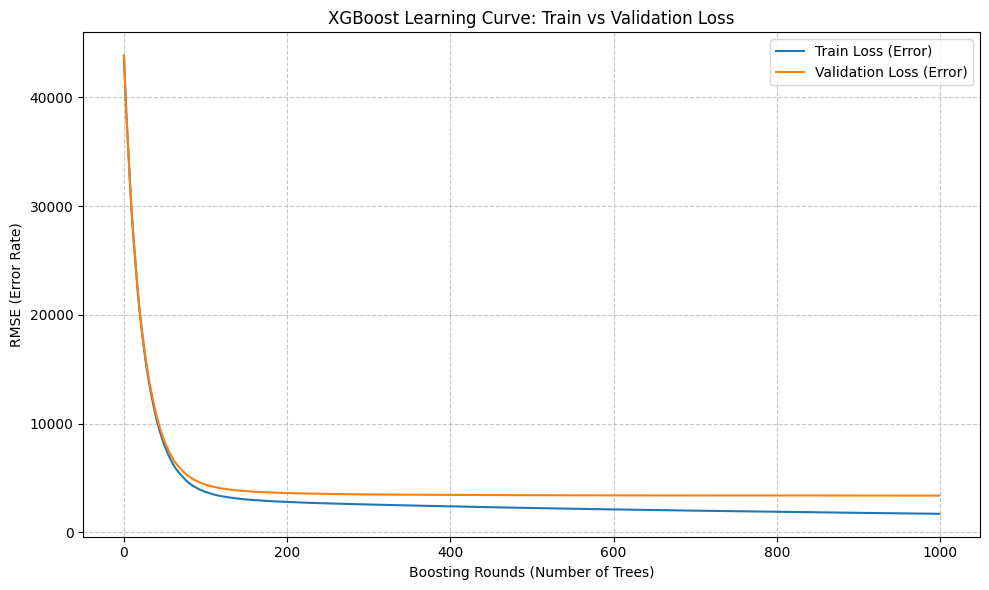

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

y_train_pred = xgb_model.predict(X_train_processed, iteration_range=(0, xgb_model.best_iteration + 1))
y_test_pred = xgb_model.predict(X_test_processed, iteration_range=(0, xgb_model.best_iteration + 1))

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

print("==================================================")
print("     OVERFITTING & UNDERFITTING DIAGNOSTICS")
print("==================================================")
print(f"TRAIN Set R2 Score : {train_r2 * 100:.2f}%")
print(f"TEST Set R2 Score  : {test_r2 * 100:.2f}%")
print("--------------------------------------------------")
print(f"TRAIN Set MAE Error: {train_mae:.2f} ETB")
print(f"TEST Set MAE Error : {test_mae:.2f} ETB")
print("==================================================")

r2_difference = train_r2 - test_r2

if r2_difference > 0.05:
    print("DIAGNOSIS: ⚠️ OVERFITTING DETECTED!")
    print("Reason: The model performs significantly better on training data than unseen data.")
elif train_r2 < 0.75 and test_r2 < 0.75:
    print("DIAGNOSIS: ⚠️ UNDERFITTING DETECTED!")
    print("Reason: The model has poor performance on both training and unseen data.")
else:
    print("DIAGNOSIS: ✅ PERFECT FIT (OPTIMAL)!")
    print("Reason: The model generalizes well and performs consistently across all datasets.")
print("==================================================\n")

results = xgb_model.evals_result()
epochs = len(results['validation_0']['rmse'])
x_axis = range(0, epochs)

plt.figure(figsize=(10, 6))
plt.plot(x_axis, results['validation_0']['rmse'], label='Train Loss (Error)')
plt.plot(x_axis, results['validation_1']['rmse'], label='Validation Loss (Error)')

plt.legend(loc='upper right')
plt.title('XGBoost Learning Curve: Train vs Validation Loss')
plt.ylabel('RMSE (Error Rate)')
plt.xlabel('Boosting Rounds (Number of Trees)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()